In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

print("Project location:", ROOT)
print("Shared folder exists:", (ROOT / "shared").exists())

if (ROOT / "shared").exists():
    print("\nFiles in shared folder:")
    for file in sorted((ROOT / "shared").iterdir()):
        print(file.name)

Project location: C:\Users\Lenovo\OneDrive - Amrita Vishwa Vidyapeetham\Desktop\Brain_Tumour_Project-main
Shared folder exists: True

Files in shared folder:
features.csv
preds_resnet.csv
preds_svm.csv
split.csv
val_probs_resnet.csv


In [2]:

import pandas as pd
import numpy as np

resnet = pd.read_csv(ROOT / "shared" / "preds_resnet.csv")
svm = pd.read_csv(ROOT / "shared" / "preds_svm.csv")
val = pd.read_csv(ROOT / "shared" / "val_probs_resnet.csv")

print("RESNET34 TEST DATA")
print("Shape:", resnet.shape)
print("Columns:", resnet.columns.tolist())
display(resnet.head())

print("\nSVM TEST DATA")
print("Shape:", svm.shape)
print("Columns:", svm.columns.tolist())
display(svm.head())

print("\nRESNET34 VALIDATION DATA")
print("Shape:", val.shape)
print("Columns:", val.columns.tolist())
display(val.head())


RESNET34 TEST DATA
Shape: (1598, 10)
Columns: ['filename', 'label', 'split', 'predicted_label', 'correct', 'prob_glioma', 'prob_meningioma', 'prob_notumor', 'prob_pituitary', 'max_confidence']


,filename,label,split,predicted_label,correct,prob_glioma,prob_meningioma,prob_notumor,prob_pituitary,max_confidence
0,Testing\glioma\Te-gl_1.jpg,glioma,test,notumor,False,0.034607,0.007739,0.954100,0.003554,0.954100
1,Testing\glioma\Te-gl_10.jpg,glioma,test,glioma,True,0.967325,0.000278,0.032266,0.000131,0.967325
2,Testing\glioma\Te-gl_100.jpg,glioma,test,glioma,True,0.704032,0.000897,0.286397,0.008674,0.704032
3,Testing\glioma\Te-gl_101.jpg,glioma,test,meningioma,False,0.169568,0.640489,0.011714,0.178229,0.640489
4,Testing\glioma\Te-gl_102.jpg,glioma,test,notumor,False,0.153889,0.002377,0.663742,0.179992,0.663742



SVM TEST DATA
Shape: (1598, 8)
Columns: ['filename', 'label', 'split', 'predicted_label', 'prob_glioma', 'prob_meningioma', 'prob_notumor', 'prob_pituitary']


,filename,label,split,predicted_label,prob_glioma,prob_meningioma,prob_notumor,prob_pituitary
0,Testing\glioma\Te-gl_1.jpg,glioma,test,notumor,0.049958,0.140175,0.739038,0.070829
1,Testing\glioma\Te-gl_10.jpg,glioma,test,glioma,0.838604,0.028326,0.041145,0.091924
2,Testing\glioma\Te-gl_100.jpg,glioma,test,glioma,0.972189,0.023985,0.002887,0.000939
3,Testing\glioma\Te-gl_101.jpg,glioma,test,notumor,0.101314,0.298441,0.512012,0.088233
4,Testing\glioma\Te-gl_102.jpg,glioma,test,pituitary,0.348036,0.004741,0.060828,0.586396



RESNET34 VALIDATION DATA
Shape: (754, 13)
Columns: ['filename', 'label', 'split', 'predicted_label', 'logit_glioma', 'logit_meningioma', 'logit_notumor', 'logit_pituitary', 'prob_glioma', 'prob_meningioma', 'prob_notumor', 'prob_pituitary', 'max_confidence']


,filename,label,split,predicted_label,logit_glioma,logit_meningioma,logit_notumor,logit_pituitary,prob_glioma,prob_meningioma,prob_notumor,prob_pituitary,max_confidence
0,Training\glioma\Tr-gl_1004.jpg,glioma,val,glioma,3.518907,1.062606,-0.976505,-0.953285,0.902255,0.077370,0.010069,0.010306,0.902255
1,Training\glioma\Tr-gl_1005.jpg,glioma,val,glioma,6.107996,-2.580614,0.700033,-2.616531,0.995211,0.000168,0.004459,0.000162,0.995211
2,Training\glioma\Tr-gl_1007.jpg,glioma,val,glioma,5.736076,-2.540255,3.013131,-2.634011,0.937939,0.000239,0.061605,0.000217,0.937939
3,Training\glioma\Tr-gl_1037.jpg,glioma,val,glioma,7.025739,-0.419621,3.042298,-4.704861,0.981149,0.000573,0.018270,0.000008,0.981149
4,Training\glioma\Tr-gl_1051.jpg,glioma,val,glioma,7.252338,-0.527988,-1.066635,-2.822864,0.999297,0.000418,0.000244,0.000042,0.999297


In [3]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Check the columns before calculating metrics
print("ResNet columns:", resnet.columns.tolist())
print("SVM columns:", svm.columns.tolist())


ResNet columns: ['filename', 'label', 'split', 'predicted_label', 'correct', 'prob_glioma', 'prob_meningioma', 'prob_notumor', 'prob_pituitary', 'max_confidence']
SVM columns: ['filename', 'label', 'split', 'predicted_label', 'prob_glioma', 'prob_meningioma', 'prob_notumor', 'prob_pituitary']



SVM
Accuracy: 0.7196

Classification report:
              precision    recall  f1-score   support

      glioma       0.68      0.57      0.62       399
  meningioma       0.64      0.55      0.59       399
     notumor       0.68      0.87      0.76       400
   pituitary       0.87      0.90      0.88       400

    accuracy                           0.72      1598
   macro avg       0.72      0.72      0.71      1598
weighted avg       0.72      0.72      0.71      1598



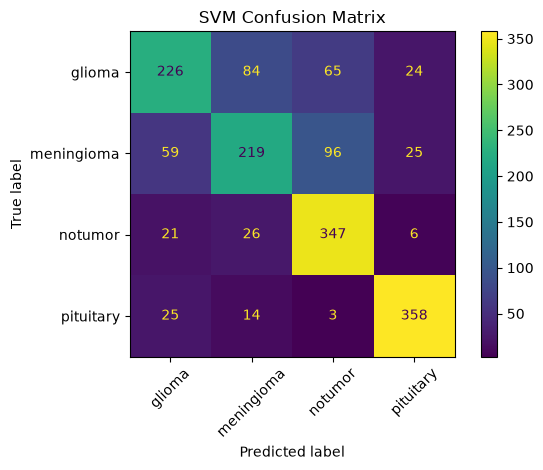


ResNet34
Accuracy: 0.8023

Classification report:
              precision    recall  f1-score   support

      glioma       0.91      0.71      0.80       399
  meningioma       0.84      0.52      0.64       399
     notumor       0.78      0.99      0.87       400
   pituitary       0.75      0.99      0.85       400

    accuracy                           0.80      1598
   macro avg       0.82      0.80      0.79      1598
weighted avg       0.82      0.80      0.79      1598



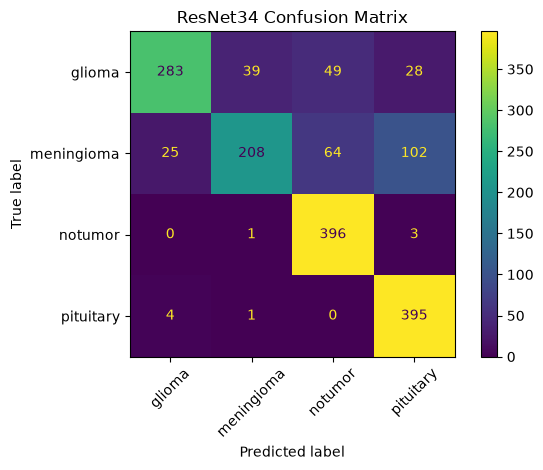

In [4]:

CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]

for name, df in [("SVM", svm), ("ResNet34", resnet)]:
    print(f"\n{'=' * 45}")
    print(name)
    print("=" * 45)

    print("Accuracy:", round(
        accuracy_score(df["label"], df["predicted_label"]), 4
    ))

    print("\nClassification report:")
    print(classification_report(
        df["label"],
        df["predicted_label"],
        labels=CLASSES,
        zero_division=0
    ))

    cm = confusion_matrix(
        df["label"],
        df["predicted_label"],
        labels=CLASSES
    )

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASSES
    )

    display_matrix.plot(xticks_rotation=45)
    plt.title(f"{name} Confusion Matrix")
    plt.tight_layout()
    plt.show()


In [5]:

from scipy.optimize import minimize_scalar
from scipy.special import softmax, logsumexp

# The four classes must be in the same order as the logit columns.
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]

# Read validation outputs.
val = pd.read_csv(ROOT / "shared" / "val_probs_resnet.csv")

print("Validation columns:")
print(val.columns.tolist())

display(val.head())


Validation columns:
['filename', 'label', 'split', 'predicted_label', 'logit_glioma', 'logit_meningioma', 'logit_notumor', 'logit_pituitary', 'prob_glioma', 'prob_meningioma', 'prob_notumor', 'prob_pituitary', 'max_confidence']


,filename,label,split,predicted_label,logit_glioma,logit_meningioma,logit_notumor,logit_pituitary,prob_glioma,prob_meningioma,prob_notumor,prob_pituitary,max_confidence
0,Training\glioma\Tr-gl_1004.jpg,glioma,val,glioma,3.518907,1.062606,-0.976505,-0.953285,0.902255,0.077370,0.010069,0.010306,0.902255
1,Training\glioma\Tr-gl_1005.jpg,glioma,val,glioma,6.107996,-2.580614,0.700033,-2.616531,0.995211,0.000168,0.004459,0.000162,0.995211
2,Training\glioma\Tr-gl_1007.jpg,glioma,val,glioma,5.736076,-2.540255,3.013131,-2.634011,0.937939,0.000239,0.061605,0.000217,0.937939
3,Training\glioma\Tr-gl_1037.jpg,glioma,val,glioma,7.025739,-0.419621,3.042298,-4.704861,0.981149,0.000573,0.018270,0.000008,0.981149
4,Training\glioma\Tr-gl_1051.jpg,glioma,val,glioma,7.252338,-0.527988,-1.066635,-2.822864,0.999297,0.000418,0.000244,0.000042,0.999297


In [6]:

# Extract the validation logits and actual labels.

logit_cols = [
    "logit_glioma",
    "logit_meningioma",
    "logit_notumor",
    "logit_pituitary"
]

X_val = val[logit_cols].to_numpy(dtype=float)

label_to_id = {
    name: i for i, name in enumerate(CLASSES)
}

y_val = val["label"].map(label_to_id).to_numpy()

# Check that the data is valid.
assert not np.isnan(X_val).any(), "Missing values in logits!"
assert not np.isnan(y_val).any(), "Unknown class labels!"

print("Validation samples:", len(val))
print("Logits shape:", X_val.shape)
print("Classes:", CLASSES)
print("Data check passed!")


Validation samples: 754
Logits shape: (754, 4)
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Data check passed!


In [7]:

def mean_nll(logits, labels, temperature):
    scaled_logits = logits / temperature

    log_probs = (
        scaled_logits
        - logsumexp(
            scaled_logits,
            axis=1,
            keepdims=True
        )
    )

    return -np.mean(
        log_probs[np.arange(len(labels)), labels]
    )


# Measure calibration before temperature scaling.
nll_before = mean_nll(X_val, y_val, 1.0)

# Find the temperature that minimizes validation NLL.
result = minimize_scalar(
    lambda t: mean_nll(X_val, y_val, t),
    bounds=(0.05, 10.0),
    method="bounded"
)

temperature = float(result.x)

nll_after = mean_nll(
    X_val, y_val, temperature
)

print("Learned temperature:", round(temperature, 4))
print("Validation NLL before:", round(nll_before, 4))
print("Validation NLL after:", round(nll_after, 4))

if nll_after < nll_before:
    print("Calibration improved validation NLL.")
else:
    print("Calibration did not improve validation NLL.")


Learned temperature: 1.1155
Validation NLL before: 0.3387
Validation NLL after: 0.3358
Calibration improved validation NLL.


In [8]:

# Convert the original logits into probabilities.
raw_val_probs = softmax(X_val, axis=1)

# Apply the learned temperature.
cal_val_probs = softmax(
    X_val / temperature,
    axis=1
)

# Find the model's highest confidence for each image.
raw_conf = raw_val_probs.max(axis=1)
cal_conf = cal_val_probs.max(axis=1)

# Check whether the predicted classes are correct.
raw_correct = (
    raw_val_probs.argmax(axis=1) == y_val
)

cal_correct = (
    cal_val_probs.argmax(axis=1) == y_val
)

print("Raw mean confidence:", round(raw_conf.mean(), 4))
print("Calibrated mean confidence:", round(cal_conf.mean(), 4))

print("Raw validation accuracy:", round(raw_correct.mean(), 4))
print("Calibrated validation accuracy:", round(cal_correct.mean(), 4))


Raw mean confidence: 0.9005
Calibrated mean confidence: 0.8848
Raw validation accuracy: 0.8859
Calibrated validation accuracy: 0.8859


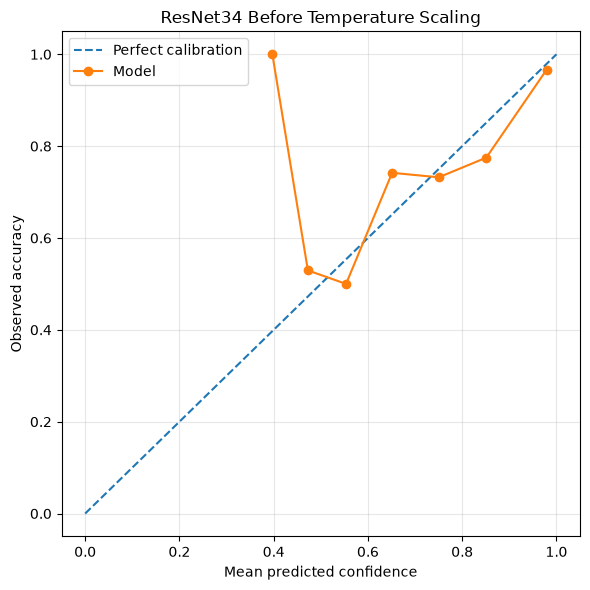

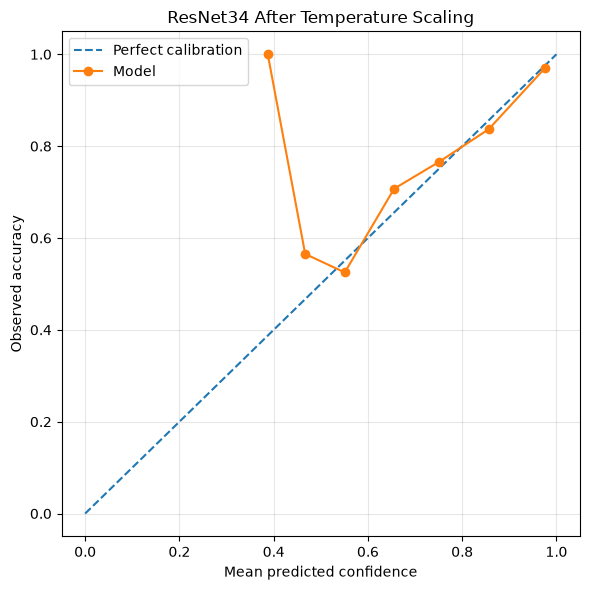

In [9]:

from sklearn.calibration import calibration_curve

def plot_reliability(confidence, correct, title, filename):
    observed_accuracy, mean_confidence = calibration_curve(
        correct.astype(int),
        confidence,
        n_bins=10,
        strategy="uniform"
    )

    plt.figure(figsize=(6, 6))

    plt.plot(
        [0, 1], [0, 1],
        linestyle="--",
        label="Perfect calibration"
    )

    plt.plot(
        mean_confidence,
        observed_accuracy,
        marker="o",
        label="Model"
    )

    plt.xlabel("Mean predicted confidence")
    plt.ylabel("Observed accuracy")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        ROOT / "outputs" / filename,
        dpi=200
    )

    plt.show()


# Before calibration
plot_reliability(
    raw_conf,
    raw_correct,
    "ResNet34 Before Temperature Scaling",
    "reliability_before.png"
)

# After calibration
plot_reliability(
    cal_conf,
    cal_correct,
    "ResNet34 After Temperature Scaling",
    "reliability_after.png"
)


In [10]:

def expected_calibration_error(confidence, correct, n_bins=10):
    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):
        if i == n_bins - 1:
            mask = (
                (confidence >= edges[i]) &
                (confidence <= edges[i + 1])
            )
        else:
            mask = (
                (confidence >= edges[i]) &
                (confidence < edges[i + 1])
            )

        if mask.sum() == 0:
            continue

        accuracy_in_bin = correct[mask].mean()
        confidence_in_bin = confidence[mask].mean()

        ece += (
            mask.mean() *
            abs(accuracy_in_bin - confidence_in_bin)
        )

    return ece


ece_before = expected_calibration_error(
    raw_conf, raw_correct
)

ece_after = expected_calibration_error(
    cal_conf, cal_correct
)

print(f"ECE before calibration: {ece_before:.4f}")
print(f"ECE after calibration:  {ece_after:.4f}")


ECE before calibration: 0.0278
ECE after calibration:  0.0162


In [11]:

TARGET_ACCEPTED_ACCURACY = 0.90

candidate_thresholds = np.unique(
    np.r_[0.0, cal_conf, 1.0]
)

best_threshold = None
best_coverage = -1.0

for threshold in candidate_thresholds:
    accepted = cal_conf >= threshold

    if accepted.sum() == 0:
        continue

    accepted_accuracy = cal_correct[accepted].mean()
    coverage = accepted.mean()

    if (
        accepted_accuracy >= TARGET_ACCEPTED_ACCURACY
        and coverage > best_coverage
    ):
        best_threshold = float(threshold)
        best_coverage = float(coverage)

if best_threshold is None:
    print("No threshold met the target.")
    print("Report this result; do not force a threshold.")
else:
    print(f"Chosen threshold: {best_threshold:.4f}")
    print(f"Validation coverage: {best_coverage:.2%}")
    print(f"Validation review rate: {1 - best_coverage:.2%}")


Chosen threshold: 0.5251
Validation coverage: 95.89%
Validation review rate: 4.11%


In [12]:

# Convert saved test probabilities to equivalent logits.
prob_cols = [f"prob_{c}" for c in CLASSES]

test_probs_raw = resnet[prob_cols].to_numpy(dtype=float)
test_probs_raw = np.clip(test_probs_raw, 1e-12, 1.0)

test_logits = np.log(test_probs_raw)

# Apply the temperature learned on validation data.
test_probs_cal = softmax(
    test_logits / temperature,
    axis=1
)

test_conf = test_probs_cal.max(axis=1)
test_pred = test_probs_cal.argmax(axis=1)

test_labels = resnet["label"].map(
    {name: i for i, name in enumerate(CLASSES)}
).to_numpy()

if best_threshold is not None:
    accepted = test_conf >= best_threshold
    review = ~accepted

    print(f"Test review rate: {review.mean():.2%}")
    print(f"Test coverage: {accepted.mean():.2%}")

    if accepted.any():
        selective_accuracy = np.mean(
            test_pred[accepted] == test_labels[accepted]
        )
        print(
            f"Test selective accuracy: "
            f"{selective_accuracy:.2%}"
        )
    else:
        print("No test predictions were accepted.")


Test review rate: 6.70%
Test coverage: 93.30%
Test selective accuracy: 83.43%


In [13]:

if best_threshold is not None:
    output = resnet[
        ["filename", "label", "predicted_label"]
    ].copy()

    output["calibrated_confidence"] = test_conf

    output["review_warning"] = (
        test_conf < best_threshold
    )

    output["decision"] = np.where(
        output["review_warning"],
        "Refer for human review",
        "Prediction available"
    )

    member_d_dir = ROOT / "outputs" / "member_d"
    member_d_dir.mkdir(parents=True, exist_ok=True)

    output.to_csv(
        member_d_dir / "review_warnings.csv",
        index=False
    )

    print("Saved review warnings successfully.")
    display(output.head(10))


Saved review warnings successfully.


,filename,label,predicted_label,calibrated_confidence,review_warning,decision
0,Testing\glioma\Te-gl_1.jpg,glioma,notumor,0.933598,False,Prediction available
1,Testing\glioma\Te-gl_10.jpg,glioma,glioma,0.953802,False,Prediction available
2,Testing\glioma\Te-gl_100.jpg,glioma,glioma,0.680992,False,Prediction available
3,Testing\glioma\Te-gl_101.jpg,glioma,meningioma,0.606382,False,Prediction available
4,Testing\glioma\Te-gl_102.jpg,glioma,notumor,0.630306,False,Prediction available
5,Testing\glioma\Te-gl_103.jpg,glioma,pituitary,0.398189,True,Refer for human review
6,Testing\glioma\Te-gl_104.jpg,glioma,glioma,0.718316,False,Prediction available
7,Testing\glioma\Te-gl_105.jpg,glioma,glioma,0.814785,False,Prediction available
8,Testing\glioma\Te-gl_106.jpg,glioma,notumor,0.895295,False,Prediction available
9,Testing\glioma\Te-gl_107.jpg,glioma,glioma,0.991390,False,Prediction available


In [14]:

print("SELECTED REVIEW THRESHOLD")
print("-------------------------")

if best_threshold is None:
    print("No threshold met the validation target.")
else:
    print(f"Threshold: {best_threshold:.4f}")
    print(f"Validation coverage: {best_coverage:.2%}")
    print(f"Validation review rate: {1 - best_coverage:.2%}")

print("\nTEST REVIEW STATISTICS")
print("----------------------")

if best_threshold is not None:
    accepted = test_conf >= best_threshold
    review = ~accepted

    print(f"Total test images: {len(test_conf)}")
    print(f"Accepted predictions: {accepted.sum()}")
    print(f"Referred for review: {review.sum()}")
    print(f"Test coverage: {accepted.mean():.2%}")
    print(f"Test review rate: {review.mean():.2%}")

    if accepted.any():
        selective_accuracy = np.mean(
            test_pred[accepted] == test_labels[accepted]
        )
        print(
            f"Accuracy on accepted predictions: "
            f"{selective_accuracy:.2%}"
        )


SELECTED REVIEW THRESHOLD
-------------------------
Threshold: 0.5251
Validation coverage: 95.89%
Validation review rate: 4.11%

TEST REVIEW STATISTICS
----------------------
Total test images: 1598
Accepted predictions: 1491
Referred for review: 107
Test coverage: 93.30%
Test review rate: 6.70%
Accuracy on accepted predictions: 83.43%


In [15]:

from sklearn.metrics import confusion_matrix

for name, df in [
    ("SVM", svm),
    ("ResNet34", resnet)
]:
    actual_tumor = df["label"] != "notumor"
    predicted_tumor = df["predicted_label"] != "notumor"

    tn, fp, fn, tp = confusion_matrix(
        actual_tumor,
        predicted_tumor,
        labels=[False, True]
    ).ravel()

    sensitivity = tp / (tp + fn) if tp + fn else 0
    specificity = tn / (tn + fp) if tn + fp else 0

    print(f"\n{name}")
    print(f"Tumor sensitivity: {sensitivity:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print(f"True positives: {tp}")
    print(f"False negatives: {fn}")
    print(f"True negatives: {tn}")
    print(f"False positives: {fp}")



SVM
Tumor sensitivity: 0.8631
Specificity: 0.8675
True positives: 1034
False negatives: 164
True negatives: 347
False positives: 53

ResNet34
Tumor sensitivity: 0.9057
Specificity: 0.9900
True positives: 1085
False negatives: 113
True negatives: 396
False positives: 4


In [16]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]

def calculate_metrics(df, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(
            df["label"], df["predicted_label"]
        ),
        "Macro Precision": precision_score(
            df["label"], df["predicted_label"],
            labels=CLASSES, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            df["label"], df["predicted_label"],
            labels=CLASSES, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            df["label"], df["predicted_label"],
            labels=CLASSES, average="macro", zero_division=0
        )
    }

comparison = pd.DataFrame([
    calculate_metrics(svm, "SVM"),
    calculate_metrics(resnet, "ResNet34")
])

display(comparison.round(4))

member_d_dir = ROOT / "outputs" / "member_d"
member_d_dir.mkdir(parents=True, exist_ok=True)

comparison.to_csv(
    member_d_dir / "final_model_comparison.csv",
    index=False
)

print("Saved final model comparison.")


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,SVM,0.7196,0.7168,0.7194,0.7130
1,ResNet34,0.8023,0.8171,0.8020,0.7902


Saved final model comparison.


In [17]:

calibration_summary = pd.DataFrame([
    {
        "Stage": "Before calibration",
        "Temperature": 1.0,
        "Validation NLL": nll_before,
        "Validation ECE": ece_before,
        "Mean confidence": raw_conf.mean(),
        "Validation accuracy": raw_correct.mean()
    },
    {
        "Stage": "After calibration",
        "Temperature": temperature,
        "Validation NLL": nll_after,
        "Validation ECE": ece_after,
        "Mean confidence": cal_conf.mean(),
        "Validation accuracy": cal_correct.mean()
    }
])

display(calibration_summary.round(4))

calibration_summary.to_csv(
    member_d_dir / "calibration_summary.csv",
    index=False
)

print("Saved calibration summary.")


,Stage,Temperature,Validation NLL,Validation ECE,Mean confidence,Validation accuracy
0,Before calibration,1.0000,0.3387,0.0278,0.9005,0.8859
1,After calibration,1.1155,0.3358,0.0162,0.8848,0.8859


Saved calibration summary.


In [18]:

binary_results = []

for name, df in [("SVM", svm), ("ResNet34", resnet)]:
    actual_tumor = df["label"] != "notumor"
    predicted_tumor = df["predicted_label"] != "notumor"

    tn, fp, fn, tp = confusion_matrix(
        actual_tumor,
        predicted_tumor,
        labels=[False, True]
    ).ravel()

    binary_results.append({
        "Model": name,
        "Tumor Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "TP": tp,
        "FN": fn,
        "TN": tn,
        "FP": fp
    })

binary_results = pd.DataFrame(binary_results)

display(binary_results.round(4))

binary_results.to_csv(
    member_d_dir / "tumor_sensitivity_specificity.csv",
    index=False
)

print("Saved tumor evaluation.")


,Model,Tumor Sensitivity,Specificity,TP,FN,TN,FP
0,SVM,0.8631,0.8675,1034,164,347,53
1,ResNet34,0.9057,0.9900,1085,113,396,4


Saved tumor evaluation.


In [19]:

summary_text = f"""
MEMBER D: CONFIDENCE AND PERFORMANCE EVALUATION

1. Calibration
Validation accuracy before calibration: {raw_correct.mean():.4f}
Validation accuracy after calibration:  {cal_correct.mean():.4f}

Mean confidence before calibration: {raw_conf.mean():.4f}
Mean confidence after calibration:  {cal_conf.mean():.4f}

ECE before calibration: {ece_before:.4f}
ECE after calibration:  {ece_after:.4f}

Learned temperature: {temperature:.4f}
Validation NLL before: {nll_before:.4f}
Validation NLL after:  {nll_after:.4f}

2. Review policy
Selected threshold: {best_threshold}
Validation coverage: {best_coverage}
"""

report_path = member_d_dir / "member_d_summary.txt"
report_path.write_text(summary_text, encoding="utf-8")

print(summary_text)
print("Saved:", report_path)



MEMBER D: CONFIDENCE AND PERFORMANCE EVALUATION

1. Calibration
Validation accuracy before calibration: 0.8859
Validation accuracy after calibration:  0.8859

Mean confidence before calibration: 0.9005
Mean confidence after calibration:  0.8848

ECE before calibration: 0.0278
ECE after calibration:  0.0162

Learned temperature: 1.1155
Validation NLL before: 0.3387
Validation NLL after:  0.3358

2. Review policy
Selected threshold: 0.5250710882178092
Validation coverage: 0.9588859416445623

Saved: C:\Users\Lenovo\OneDrive - Amrita Vishwa Vidyapeetham\Desktop\Brain_Tumour_Project-main\outputs\member_d\member_d_summary.txt


In [20]:

print("MEMBER D DELIVERABLE CHECK")
print("=" * 35)

required_files = [
    "final_model_comparison.csv",
    "calibration_summary.csv",
    "tumor_sensitivity_specificity.csv",
    "review_warnings.csv",
    "member_d_summary.txt"
]

for filename in required_files:
    path = member_d_dir / filename
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{filename}: {status}")

print("\nReliability diagrams:")

for filename in [
    "reliability_before.png",
    "reliability_after.png"
]:
    path = ROOT / "outputs" / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'MISSING'}")

print("\nFinal model comparison:")
comparison_path = member_d_dir / "final_model_comparison.csv"

if comparison_path.exists():
    display(pd.read_csv(comparison_path))
else:
    print("Run the model comparison cell to create this file.")


MEMBER D DELIVERABLE CHECK
final_model_comparison.csv: FOUND
calibration_summary.csv: FOUND
tumor_sensitivity_specificity.csv: FOUND
review_warnings.csv: FOUND
member_d_summary.txt: FOUND

Reliability diagrams:
reliability_before.png: FOUND
reliability_after.png: FOUND

Final model comparison:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,SVM,0.719650,0.716788,0.719447,0.712991
1,ResNet34,0.802253,0.817124,0.802019,0.790154


In [21]:
resnet_check = resnet[["filename", "label"]].sort_values(
    ["filename", "label"]
).reset_index(drop=True)

svm_check = svm[["filename", "label"]].sort_values(
    ["filename", "label"]
).reset_index(drop=True)

print("Same test images and labels:", resnet_check.equals(svm_check))

Same test images and labels: True


In [22]:
final_results = f"""
MEMBER 4: FINAL EVALUATION

Test review rate: {review.mean():.2%}
Test coverage: {accepted.mean():.2%}
Accuracy on accepted predictions: {selective_accuracy:.2%}

Validation ECE before calibration: {ece_before:.4f}
Validation ECE after calibration: {ece_after:.4f}

Validation NLL before calibration: {nll_before:.4f}
Validation NLL after calibration: {nll_after:.4f}

Selected confidence threshold: {best_threshold:.4f}
"""

print(final_results)

with open(member_d_dir / "member_d_summary.txt", "a", encoding="utf-8") as f:
    f.write("\n" + final_results)

print("Final results saved.")


MEMBER 4: FINAL EVALUATION

Test review rate: 6.70%
Test coverage: 93.30%
Accuracy on accepted predictions: 83.43%

Validation ECE before calibration: 0.0278
Validation ECE after calibration: 0.0162

Validation NLL before calibration: 0.3387
Validation NLL after calibration: 0.3358

Selected confidence threshold: 0.5251

Final results saved.


In [23]:
for file in sorted(member_d_dir.iterdir()):
    print(file.name)

calibration_summary.csv
final_model_comparison.csv
member_d_summary.txt
review_warnings.csv
tumor_sensitivity_specificity.csv
